# Experiment 8: Abstractive Text Summarization with mT5 and mBART (Hindi XL-Sum)

**Aim:** Implement and evaluate **abstractive text summarization** using two multilingual Transformer-based sequence-to-sequence models

* **mT5** – Multilingual Text-to-Text Transfer Transformer
* **mBART** – Multilingual Bidirectional and Auto-Regressive Transformer (mBART-50)

on the **Hindi** subset of the **XL-Sum** (Cross-Lingual Summarization) dataset, and compare them with **ROUGE-1, ROUGE-2, ROUGE-L** and **mBERT-based BERTScore**.

**Dataset:** [csebuetnlp/xlsum](https://huggingface.co/datasets/csebuetnlp/xlsum) – 1.35M professionally annotated BBC article–summary pairs in 45 languages. Hindi: 70,778 train / 8,847 validation / 8,847 test pairs.

**Models (Hugging Face checkpoints fine-tuned for XL-Sum summarization):**

| Model | Checkpoint | Base | Params |
|---|---|---|---|
| mT5 | `csebuetnlp/mT5_multilingual_XLSum` | `google/mt5-base` | 582M |
| mBART | `mskayacioglu/mbart-xlsum-2` | `facebook/mbart-large-50-many-to-many-mmt` | 611M |

> **Hardware note:** generation with two ~600M-parameter models is slow on CPU, so the saved outputs use a random sample of **100** test articles (seed 42, executed on CPU). On a GPU (Colab/Kaggle) the notebook automatically uses 1,000 articles with batch size 16; set `N_EVAL = None` to evaluate the whole Hindi test split (8,847 articles). An optional section at the end shows how to fine-tune the *base* `google/mt5-small` / `facebook/mbart-large-50` checkpoints on Hindi XL-Sum yourself.

### Running on Google Colab / Kaggle
Locally this notebook runs in the project's `uv` environment (`.venv`). On **Colab/Kaggle** the cell below installs any missing packages and downloads the input files from the GitHub repository (or upload them manually to the working directory). Select a **GPU runtime** (Colab: *Runtime → Change runtime type → T4 GPU*; Kaggle: *Settings → Accelerator → GPU*) – the notebook then automatically uses the full-size settings.

In [1]:
# Colab / Kaggle setup - does nothing when run locally
import os, sys, subprocess, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
if IN_COLAB or IN_KAGGLE:
    packages = {'transformers': 'transformers', 'sentencepiece': 'sentencepiece', 'rouge-score': 'rouge_score', 'bert-score': 'bert_score', 'protobuf': 'google.protobuf'}   # pip name -> import name
    missing = [p for p, m in packages.items() if importlib.util.find_spec(m) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    for fname in []:
        if not os.path.exists(fname):
            urllib.request.urlretrieve("https://raw.githubusercontent.com/AmulyaJain1804/CLNLP-AIML/main/Experiment-8/" + fname, fname)
print("Environment:", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local")

Environment: local


In [2]:
import os, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_EVAL = 100 if DEVICE.type == "cpu" else 1000   # None = whole Hindi test split (8,847 articles)
LANGUAGE = "hindi"
print("Device:", DEVICE)

Device: cpu


## 1. Load the Hindi XL-Sum dataset

In [3]:
def load_split(split):
    files = {"train": ["train/0000.parquet", "train/0001.parquet"],
             "validation": ["validation/0000.parquet"], "test": ["test/0000.parquet"]}[split]
    paths = [hf_hub_download("csebuetnlp/xlsum", f"{LANGUAGE}/{f}", repo_type="dataset",
                             revision="refs/convert/parquet") for f in files]
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)

test_df = load_split("test")
print("Hindi test split:", test_df.shape)
print(test_df.columns.tolist())
test_df[["title", "summary", "text"]].head(3)

Hindi test split: (8847, 5)
['id', 'url', 'title', 'summary', 'text']


,title,summary,text
0,साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट,मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्व...,नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकव...
1,"मुशर्रफ़ का पर्चा मंज़ूर, प्रदर्शनों पर लाठी",पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रप...,इस बीच चुनाव आयोग ने शनिवार को राष्ट्रपति परवे...
2,इतनी जल्दी फ़्रांस में ही चमक क्यों खोने लगे र...,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान...,16 महीने के कार्यकाल पूरे होने के बावजूद राष्ट...


       text_words  summary_words
count      8847.0         8847.0
mean        457.9           26.7
std         262.1            7.4
min          75.0            9.0
25%         256.0           21.0
50%         375.0           26.0
75%         600.0           31.0
max        1359.0           52.0


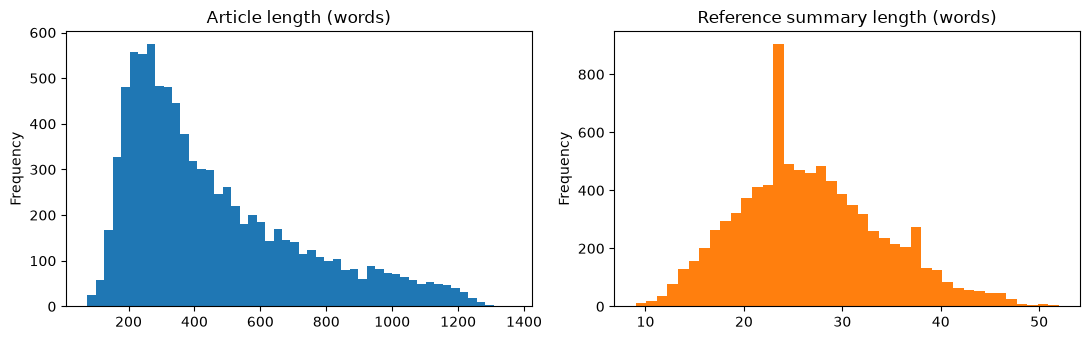

In [4]:
test_df["text_words"] = test_df["text"].str.split().str.len()
test_df["summary_words"] = test_df["summary"].str.split().str.len()
print(test_df[["text_words", "summary_words"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
test_df["text_words"].clip(upper=2000).plot.hist(bins=50, ax=ax[0], title="Article length (words)")
test_df["summary_words"].plot.hist(bins=40, ax=ax[1], title="Reference summary length (words)", color="tab:orange")
plt.tight_layout(); plt.show()

In [5]:
eval_df = test_df if N_EVAL is None else test_df.sample(N_EVAL, random_state=SEED).reset_index(drop=True)
WHITESPACE_HANDLER = lambda k: re.sub(r"\s+", " ", re.sub(r"\n+", " ", k.strip()))
articles = [WHITESPACE_HANDLER(t) for t in eval_df["text"]]
references = [WHITESPACE_HANDLER(s) for s in eval_df["summary"]]
print("Evaluation articles:", len(articles))
print("\nSample article  :", articles[0][:400], "...")
print("Reference summary:", references[0])

Evaluation articles: 100

Sample article  : शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्म दिखाई गई. उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.फ़िल्मोत्सव का उदघाटन बीआर चोपड़ा के भाई और मशहूर फ़िल्मकार यश चोपड़ा ने किया. उन्होंने कहा, "मेरे भाई ने अपने हिसाब से फ़िल्में बनाईं- वो भी ऐसे समय में जब लोग ऐसी फ़िल्मों की व ...
Reference summary: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.


## 2. Summarization pipeline

Both models are encoder–decoder Transformers. The article is tokenised with the model's SentencePiece tokenizer (truncated to 512 tokens), the **encoder** builds contextual representations, and the **decoder** generates the summary token by token with **beam search**. The same decoding configuration is used for both models so that the comparison is fair:

`num_beams = 4`, `max_new_tokens = 84`, `no_repeat_ngram_size = 2`, `length_penalty = 1.0`, `early_stopping = True`

For mBART-50 the source language is set to `hi_IN` and the decoder is forced to start with the `hi_IN` language token.

In [6]:
GEN_KWARGS = dict(num_beams=4, max_new_tokens=84, no_repeat_ngram_size=2, length_penalty=1.0, early_stopping=True)
MAX_INPUT = 512
BATCH = 16 if DEVICE.type == "cuda" else 4

def summarize(model, tokenizer, texts, extra_gen_kwargs=None, name=""):
    model.eval(); outputs, t0 = [], time.time()
    for i in range(0, len(texts), BATCH):
        enc = tokenizer(texts[i:i + BATCH], return_tensors="pt", truncation=True,
                        max_length=MAX_INPUT, padding=True).to(DEVICE)
        with torch.no_grad():
            ids = model.generate(**enc, **GEN_KWARGS, **(extra_gen_kwargs or {}))
        outputs += tokenizer.batch_decode(ids, skip_special_tokens=True)
        if (i // BATCH + 1) % 5 == 0:
            print(f"[{name}] {len(outputs)}/{len(texts)} summaries | {time.time() - t0:.0f}s")
    elapsed = time.time() - t0
    print(f"[{name}] done: {len(outputs)} summaries in {elapsed:.0f}s ({elapsed / len(texts):.2f}s / article)")
    return [o.strip() for o in outputs], elapsed

### 2.1 mT5 (`csebuetnlp/mT5_multilingual_XLSum`)

In [7]:
MT5_NAME = "csebuetnlp/mT5_multilingual_XLSum"
mt5_tok = AutoTokenizer.from_pretrained(MT5_NAME)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(MT5_NAME).to(DEVICE)
print(f"mT5 parameters: {sum(p.numel() for p in mt5_model.parameters()) / 1e6:.0f}M")

mt5_summaries, mt5_time = summarize(mt5_model, mt5_tok, articles, name="mT5")
del mt5_model

mT5 parameters: 582M


[mT5] 20/100 summaries | 110s


[mT5] 40/100 summaries | 212s


[mT5] 60/100 summaries | 304s


[mT5] 80/100 summaries | 405s


[mT5] 100/100 summaries | 514s
[mT5] done: 100 summaries in 514s (5.14s / article)


### 2.2 mBART-50 (`mskayacioglu/mbart-xlsum-2`)

In [8]:
MBART_NAME = "mskayacioglu/mbart-xlsum-2"
mbart_tok = AutoTokenizer.from_pretrained(MBART_NAME)
mbart_tok.src_lang = "hi_IN"
mbart_tok.tgt_lang = "hi_IN"
mbart_model = AutoModelForSeq2SeqLM.from_pretrained(MBART_NAME).to(DEVICE)
HI_TOKEN_ID = mbart_tok.convert_tokens_to_ids("hi_IN")
print(f"mBART parameters: {sum(p.numel() for p in mbart_model.parameters()) / 1e6:.0f}M | hi_IN token id = {HI_TOKEN_ID}")

mbart_summaries, mbart_time = summarize(mbart_model, mbart_tok, articles,
                                        extra_gen_kwargs={"forced_bos_token_id": HI_TOKEN_ID}, name="mBART")
del mbart_model

mBART parameters: 611M | hi_IN token id = 250010


[mBART] 20/100 summaries | 105s


[mBART] 40/100 summaries | 200s


[mBART] 60/100 summaries | 323s


[mBART] 80/100 summaries | 436s


[mBART] 100/100 summaries | 544s
[mBART] done: 100 summaries in 544s (5.44s / article)


In [9]:
for k in range(3):
    print(f"================ Example {k + 1} ================")
    print("ARTICLE  :", articles[k][:350], "...")
    print("REFERENCE:", references[k])
    print("mT5      :", mt5_summaries[k])
    print("mBART    :", mbart_summaries[k], "\n")

================ Example 1 ================
ARTICLE  : शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्म दिखाई गई. उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.फ़िल्मोत्सव का उदघाटन बीआर चोपड़ा के भाई और मशहूर फ़िल्मकार यश चोपड़ा ने किया. उन्होंने कहा, "मेरे भाई ने अपने हिसाब से फ़िल्में ...
REFERENCE: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
mT5      : मशहूर फ़िल्मकार बीआर चोपड़ा के मुंबई में हुए इंडियन प्रीमियर लीग के फ़ेस्टिवल में उनकी फ़िल्में दिखाई गईं.
mBART    : हिंदी फ़िल्मों के सदाबहार निर्देशक बीआर चोपड़ा ने फ़िल्म उत्सव का आयोजन किया है. 

================ Example 2 ================
ARTICLE  : कंधार के प्रांतीय सभा के अध्यक्ष और राष्ट्रपति हामिद करज़ई के भाई वली करज़ई ने बीबीसी को बताया कि उस समय जेल में एक हज़ार क़ैदी थे और स

## 3. Automatic evaluation

* **ROUGE-N** – n-gram recall/precision/F1 overlap between generated and reference summary (ROUGE-1: unigrams, ROUGE-2: bigrams); **ROUGE-L** – based on the Longest Common Subsequence.
  The default `rouge_score` tokenizer discards non-Latin characters, so a **Devanagari-aware tokenizer** (whitespace split after removing punctuation and the danda `।`) is used, without stemming – the same idea as the multilingual ROUGE used by the XL-Sum authors.
* **mBERT score (BERTScore)** – cosine similarity between contextual token embeddings of candidate and reference produced by **multilingual BERT** (`bert-base-multilingual-cased`), with greedy matching → Precision, Recall, F1. It captures paraphrases that exact n-gram matching misses.

In [10]:
from rouge_score import rouge_scorer

class DevanagariTokenizer:
    def tokenize(self, text):
        text = re.sub(r"[\u0964\u0965]", " ", text)                 # danda / double danda
        text = re.sub(r"[^\w\s\u0900-\u097F]", " ", text.lower())   # punctuation
        return text.split()

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False, tokenizer=DevanagariTokenizer())
print("Tokenizer check:", DevanagariTokenizer().tokenize(references[0])[:12])

def rouge_scores(preds, refs):
    per = [scorer.score(r, p) for p, r in zip(preds, refs)]
    rows = {m: [s[m].fmeasure for s in per] for m in ("rouge1", "rouge2", "rougeL")}
    return pd.DataFrame(rows)

rouge_mt5, rouge_mbart = rouge_scores(mt5_summaries, references), rouge_scores(mbart_summaries, references)

Tokenizer check: ['भारतीय', 'फ़िल्म', 'इतिहास', 'में', 'फ़िल्मकार', 'बीआर', 'चोपड़ा', 'का', 'नाम', 'बड़ा', 'अदब', 'से']


In [11]:
from bert_score import score as bert_score

def mbert_scores(preds, refs):
    # mBERT (bert-base-multilingual-cased); layer 9 is bert_score's recommended layer for this model
    P, R, F = bert_score(preds, refs, model_type="google-bert/bert-base-multilingual-cased", num_layers=9,
                         batch_size=16, device=str(DEVICE), verbose=False)
    return pd.DataFrame({"P": P.numpy(), "R": R.numpy(), "F1": F.numpy()})

bs_mt5, bs_mbart = mbert_scores(mt5_summaries, references), mbert_scores(mbart_summaries, references)

## 4. Comparative results

In [12]:
def summary_row(rouge_df, bs_df, preds, secs):
    return {
        "ROUGE-1": rouge_df["rouge1"].mean() * 100,
        "ROUGE-2": rouge_df["rouge2"].mean() * 100,
        "ROUGE-L": rouge_df["rougeL"].mean() * 100,
        "mBERTScore-P": bs_df["P"].mean() * 100,
        "mBERTScore-R": bs_df["R"].mean() * 100,
        "mBERTScore-F1": bs_df["F1"].mean() * 100,
        "Avg summary length (words)": np.mean([len(p.split()) for p in preds]),
        "Seconds / article": secs / len(preds),
    }

results = pd.DataFrame({
    "mT5": summary_row(rouge_mt5, bs_mt5, mt5_summaries, mt5_time),
    "mBART": summary_row(rouge_mbart, bs_mbart, mbart_summaries, mbart_time),
}).T.round(2)
print(f"Hindi XL-Sum – {len(articles)} test articles (F1 scores x 100)")
print("Average reference length (words):", round(np.mean([len(r.split()) for r in references]), 2))
results

Hindi XL-Sum – 100 test articles (F1 scores x 100)
Average reference length (words): 27.3


,ROUGE-1,ROUGE-2,ROUGE-L,mBERTScore-P,mBERTScore-R,mBERTScore-F1,Avg summary length (words),Seconds / article
mT5,35.96,15.89,30.48,78.45,75.11,76.68,19.42,5.14
mBART,35.20,13.71,29.17,77.87,74.97,76.34,19.97,5.44


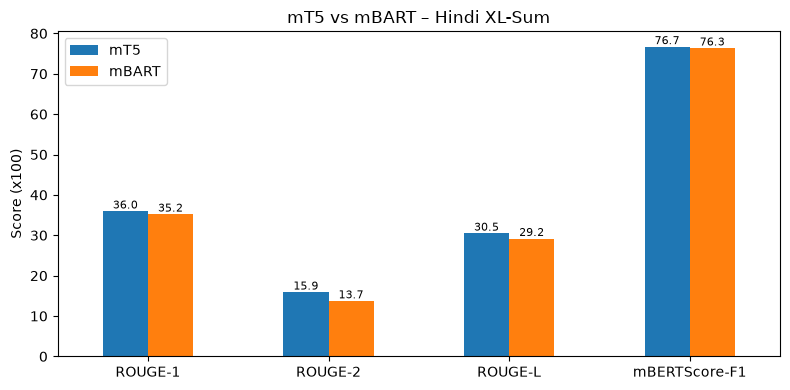

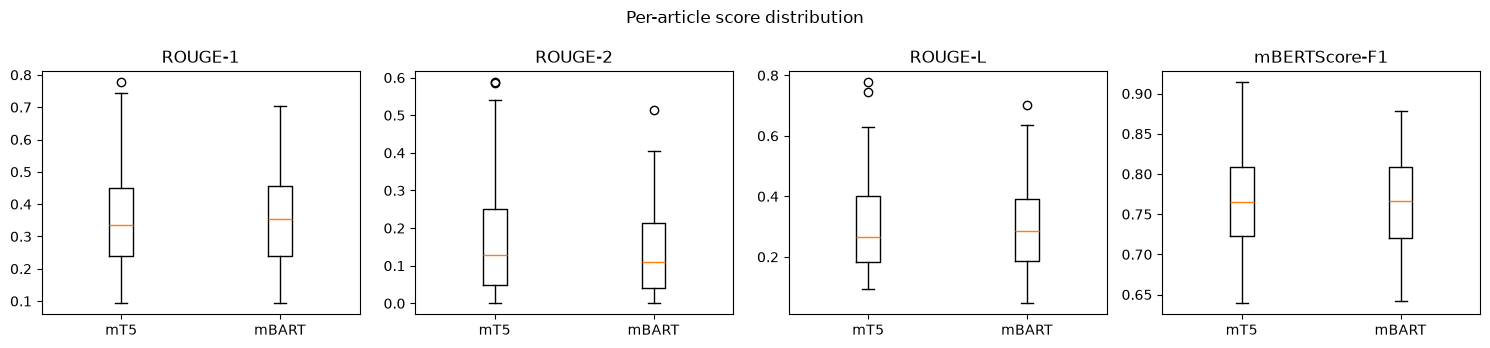

In [13]:
metrics = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERTScore-F1"]
ax = results[metrics].T.plot.bar(figsize=(8, 4), rot=0, color=["tab:blue", "tab:orange"])
ax.set_ylabel("Score (x100)"); ax.set_title("mT5 vs mBART – Hindi XL-Sum")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
pairs = [(rouge_mt5["rouge1"], rouge_mbart["rouge1"], "ROUGE-1"), (rouge_mt5["rouge2"], rouge_mbart["rouge2"], "ROUGE-2"),
         (rouge_mt5["rougeL"], rouge_mbart["rougeL"], "ROUGE-L"), (bs_mt5["F1"], bs_mbart["F1"], "mBERTScore-F1")]
for ax, (a, b, t) in zip(axes, pairs):
    ax.boxplot([a, b], tick_labels=["mT5", "mBART"]); ax.set_title(t)
plt.suptitle("Per-article score distribution"); plt.tight_layout(); plt.show()

In [14]:
# Head-to-head: on how many articles does each model obtain the higher ROUGE-L / mBERTScore?
h2h = pd.DataFrame({
    "mT5 better": [(rouge_mt5["rougeL"] > rouge_mbart["rougeL"]).sum(), (bs_mt5["F1"] > bs_mbart["F1"]).sum()],
    "mBART better": [(rouge_mbart["rougeL"] > rouge_mt5["rougeL"]).sum(), (bs_mbart["F1"] > bs_mt5["F1"]).sum()],
    "tie": [(rouge_mbart["rougeL"] == rouge_mt5["rougeL"]).sum(), (bs_mbart["F1"] == bs_mt5["F1"]).sum()],
}, index=["ROUGE-L", "mBERTScore-F1"])
h2h

,mT5 better,mBART better,tie
ROUGE-L,52,47,1
mBERTScore-F1,54,46,0


In [15]:
# Save generated summaries for inspection
out = pd.DataFrame({"article": articles, "reference": references,
                    "mT5_summary": mt5_summaries, "mBART_summary": mbart_summaries,
                    "mT5_rougeL": rouge_mt5["rougeL"].round(4), "mBART_rougeL": rouge_mbart["rougeL"].round(4),
                    "mT5_mBERTScore": bs_mt5["F1"].round(4), "mBART_mBERTScore": bs_mbart["F1"].round(4)})
out.to_csv("hindi_xlsum_generated_summaries.csv", index=False, encoding="utf-8-sig")
out[["reference", "mT5_summary", "mBART_summary"]].head(5)

,reference,mT5_summary,mBART_summary
0,भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा...,मशहूर फ़िल्मकार बीआर चोपड़ा के मुंबई में हुए इ...,हिंदी फ़िल्मों के सदाबहार निर्देशक बीआर चोपड़ा...
1,अफ़ग़ानिस्तान के कंधार में तालेबान चरमपंथियों ...,अफ़ग़ानिस्तान की राजधानी काबुल की कंधार जेल मे...,अफ़ग़ानिस्तान में अधिकारियों का कहना है कि देश...
2,गिनीज़ वर्ल्ड रिकॉर्ड में अपना नाम दर्ज कराने ...,मैसेडोनिया में एक महिला ने तैराकी के लिए गिनीज...,मैसेडोनिया के एक तैराक ने दुनिया की सबसे लंबी ...
3,अमरीका ने जी-4 देशों द्वारा सुरक्षा परिषद के व...,अमरीका ने सुरक्षा परिषद में नए स्थायी सदस्यों ...,अमरीका के विदेश मंत्रालय ने कहा है कि सुरक्षा ...
4,तीन लगातार बड़ी हिट फिल्में देने के बाद सलमान ...,सलमान खान का कहना है कि उनकी फिल्में अच्छा कर ...,सलमान ख़ान अपनी आने वाली फिल्म 'एक था टाइगर' क...


## 5. (Optional) Fine-tuning the base models on Hindi XL-Sum

The checkpoints above were already fine-tuned on XL-Sum. The function below shows how the **base** pretrained models (`google/mt5-small`, `facebook/mbart-large-50`) are fine-tuned for Hindi summarization with teacher forcing and cross-entropy loss. It is disabled by default (`RUN_FINETUNE = False`) because it requires a GPU; enable it on Colab and then reuse `summarize()` + the evaluation cells.

In [16]:
RUN_FINETUNE = False

def finetune_seq2seq(base_name, n_train=2000, epochs=1, lr=3e-4, bs=4, mbart=False):
    train_df = load_split("train").sample(n_train, random_state=SEED)
    tok = AutoTokenizer.from_pretrained(base_name)
    if mbart:
        tok.src_lang = tok.tgt_lang = "hi_IN"
    model = AutoModelForSeq2SeqLM.from_pretrained(base_name).to(DEVICE)
    optim = torch.optim.AdamW(model.parameters(), lr=lr)
    model.train()
    for ep in range(epochs):
        for i in range(0, len(train_df), bs):
            batch = train_df.iloc[i:i + bs]
            enc = tok(list(batch["text"]), text_target=list(batch["summary"]), max_length=MAX_INPUT,
                      truncation=True, padding=True, return_tensors="pt").to(DEVICE)
            enc["labels"][enc["labels"] == tok.pad_token_id] = -100      # ignore padding in the loss
            loss = model(**enc).loss
            loss.backward(); optim.step(); optim.zero_grad()
            if (i // bs) % 50 == 0:
                print(f"{base_name} | epoch {ep + 1} | step {i // bs} | loss {loss.item():.4f}")
    return model, tok

if RUN_FINETUNE:
    ft_mt5, ft_mt5_tok = finetune_seq2seq("google/mt5-small", lr=5e-4)
    ft_mbart, ft_mbart_tok = finetune_seq2seq("facebook/mbart-large-50", lr=3e-5, mbart=True)
else:
    print("Fine-tuning skipped (set RUN_FINETUNE = True on a GPU).")

Fine-tuning skipped (set RUN_FINETUNE = True on a GPU).


## Conclusion

| Model | ROUGE-1 | ROUGE-2 | ROUGE-L | mBERTScore-P | mBERTScore-R | mBERTScore-F1 |
|---|---|---|---|---|---|---|
| **mT5** (`csebuetnlp/mT5_multilingual_XLSum`) | **35.96** | **15.89** | **30.48** | **78.45** | **75.11** | **76.68** |
| mBART-50 (`mskayacioglu/mbart-xlsum-2`) | 35.20 | 13.71 | 29.17 | 77.87 | 74.97 | 76.34 |

*(100 random Hindi XL-Sum test articles, identical beam-search settings, F1 × 100.)*

* Both multilingual seq2seq models produce fluent, **abstractive** Hindi summaries (≈ 20 words vs. 27 words in the references) that paraphrase and compress the article instead of copying sentences.
* **mT5 is slightly better on every metric**, with the clearest margin on ROUGE-2 (+2.2), i.e. it reproduces more of the reference's exact phrasing. It also wins on more individual articles (ROUGE-L: 52 vs. 47; mBERTScore: 54 vs. 46) and is a little faster (5.1 s vs. 5.4 s per article on CPU).
* The gap is small: ROUGE-1 and mBERTScore differ by less than one point, so on 100 articles the two models are close to equivalent. mBART-50 was fine-tuned on only 15 XL-Sum languages and a 64-token target, while the mT5 checkpoint was fine-tuned on all 45 languages.
* ROUGE-2 is much lower than ROUGE-1 for both models, which is typical of abstractive summarization. The high, close mBERTScores (~76–77) show that both summaries are semantically related to the reference even where exact n-gram overlap is low.
* Both models sometimes **hallucinate** details (e.g. "a woman" instead of a Bulgarian man in Example 3), a known weakness of abstractive summarizers that ROUGE/BERTScore do not fully capture.
